# Assignment 4 – Reweighing (Kamiran & Calders, 2012) on Adult, German and COMPAS

**Algorithm:** Reweighing, a pre-processing method. Each (group, label) cell of the **training** data gets the weight `W(s, y) = P(s)·P(y) / P(s, y)`. This makes the protected attribute and the label statistically independent in the weighted training data. Features and labels are not changed.

**Pipeline**
1. Load and clean the dataset, then define the binary protected attribute `s` (1 = privileged) and the binary label `y` (1 = favourable).
2. **Before mitigation:** compute DP_Diff, DIR and consistency on the original labels of the full dataset.
3. Stratified 70/30 train/test split, stratified on label × group.
4. Fit Reweighing on the training split only, then train logistic regression with the weights as `sample_weight`.
5. **After mitigation:** compute DP_Diff, DIR, consistency, accuracy, balanced accuracy and F1 from the test-set predictions.
6. Reference point: the same classifier trained **without** weights (baseline).

**Metric definitions** (same as AIF360)
* DP_Diff = P(ŷ=1 | s=0) − P(ŷ=1 | s=1). 0 is fair; negative means the unprivileged group is disadvantaged.
* DIR = P(ŷ=1 | s=0) / P(ŷ=1 | s=1). 1 is fair; the 80 % rule asks for ≥ 0.8.
* Consistency = 1 − mean_i |ŷ_i − mean(ŷ over the k nearest neighbours of x_i)|, with k = 5 and neighbours found in the encoded feature space (point i included, as in AIF360).

In [0]:
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# ---- Parameters (report these in the PDF) ----
TEST_SIZE = 0.30          # stratified hold-out fraction
SEEDS = [0, 1, 2, 3, 42]  # repeated splits, reported as mean ± std
K_CONSISTENCY = 5         # neighbours for the consistency metric
LR_PARAMS = dict(C=1.0, solver="lbfgs", max_iter=2000)

# ---- Data locations ----
# DATA_DIR is the folder containing the three raw files (see README for download links).
# Locally / on Colab: DATA_DIR = "data". On Databricks: the workspace folder of this assignment.
import os
DATA_DIR = os.environ.get("DATA_DIR", "/Workspace/Users/ehab.wasel@ssc4tbi.nl/fairness_assignment4")
DATA_PATHS = {
    "adult":  os.path.join(DATA_DIR, "adult.csv"),                                   # UCI Adult (Kaggle CSV version with header)
    "german": os.path.join(DATA_DIR, "statlog+german+credit+data", "german.data"),  # UCI Statlog German Credit
    "compas": os.path.join(DATA_DIR, "propublica_data_for_fairml.csv"),             # ProPublica COMPAS, FairML version
}
for k, p in DATA_PATHS.items():
    assert os.path.exists(p), f"Missing {k} file: {p}"

In [0]:
def group_rates(y, s, w=None):
    y, s = np.asarray(y, float), np.asarray(s)
    w = np.ones(len(y)) if w is None else np.asarray(w, float)
    p_unpriv = np.average(y[s == 0], weights=w[s == 0])
    p_priv = np.average(y[s == 1], weights=w[s == 1])
    return p_unpriv, p_priv

def dp_diff(y, s, w=None):
    pu, pp = group_rates(y, s, w); return pu - pp

def disparate_impact(y, s, w=None):
    pu, pp = group_rates(y, s, w); return pu / pp

def consistency(X, y, k=K_CONSISTENCY):
    """AIF360 definition: 1 - mean |y_i - mean(y of k-NN of x_i)|."""
    y = np.asarray(y, float)
    _, idx = NearestNeighbors(n_neighbors=k).fit(X).kneighbors(X)
    return 1 - np.mean(np.abs(y - y[idx].mean(axis=1)))

class Reweighing:
    """Kamiran & Calders (2012): W(s,y) = P(s)P(y) / P(s,y), estimated on training data."""
    def fit(self, y, s):
        y, s = np.asarray(y), np.asarray(s); n = len(y)
        self.weights_ = {(sv, yv): ((s == sv).sum() * (y == yv).sum()) / (n * ((s == sv) & (y == yv)).sum())
                         for sv in (0, 1) for yv in (0, 1)}
        return self
    def transform(self, y, s):
        return np.array([self.weights_[(si, yi)] for si, yi in zip(np.asarray(s), np.asarray(y))])

# Sanity check on a toy example with a known answer:
# s=1: 3 positives / 1 negative, s=0: 1 positive / 3 negatives -> W(1,1)=W(0,0)=(4*4)/(8*3)=0.667, W(1,0)=W(0,1)=(4*4)/(8*1)=2
y_toy = np.array([1,1,1,0, 1,0,0,0]); s_toy = np.array([1,1,1,1, 0,0,0,0])
rw_toy = Reweighing().fit(y_toy, s_toy)
print(rw_toy.weights_)
assert abs(dp_diff(y_toy, s_toy, rw_toy.transform(y_toy, s_toy))) < 1e-12
print("Toy check passed: weighted DP_Diff = 0")

{(0, 0): np.float64(0.6666666666666666), (0, 1): np.float64(2.0), (1, 0): np.float64(2.0), (1, 1): np.float64(0.6666666666666666)}
Toy check passed: weighted DP_Diff = 0


In [0]:
def _read_csv(path, **kw):
    return pd.read_csv(path, skipinitialspace=True, **kw)

def load_adult(path):
    """Protected attribute: sex (Male = privileged). Favourable label: income >50K."""
    d = _read_csv(path).replace("?", np.nan).dropna()
    d["y"] = (d["income"].str.strip() == ">50K").astype(int)
    d["s"] = (d["sex"] == "Male").astype(int)
    cat = ["workclass", "marital.status", "occupation", "relationship", "race", "sex", "native.country"]
    num = ["age", "education.num", "capital.gain", "capital.loss", "hours.per.week"]  # 'education' duplicates education.num; fnlwgt is a sampling weight
    return d, cat, num, "sex (Male=priv.)"

GERMAN_COLS = ["status", "duration", "credit_history", "purpose", "credit_amount", "savings", "employment",
               "installment_rate", "personal_status", "other_debtors", "residence_since", "property", "age",
               "installment_plans", "housing", "existing_credits", "job", "num_liable", "telephone",
               "foreign_worker", "credit"]
def load_german(path):
    """UCI german.data. Protected attribute: age > 25 (privileged, as in AIF360). Favourable label: good credit (1)."""
    d = pd.read_csv(path, sep=r"\s+", header=None, names=GERMAN_COLS)
    d["y"] = (d["credit"] == 1).astype(int)
    d["s"] = (d["age"] > 25).astype(int)
    d["sex"] = np.where(d["personal_status"].isin(["A92", "A95"]), "female", "male")
    cat = ["status", "credit_history", "purpose", "savings", "employment", "other_debtors", "property",
           "installment_plans", "housing", "job", "telephone", "foreign_worker", "sex"]
    num = ["duration", "credit_amount", "installment_rate", "residence_since", "age", "existing_credits", "num_liable"]
    return d, cat, num, "age (>25=priv.)"

def load_compas(path):
    """ProPublica two-year recidivism data, FairML version (propublica_data_for_fairml.csv, already
    filtered by ProPublica). Protected attribute: race, African-American = unprivileged (s=0), all other
    races = privileged (s=1). Favourable label: no recidivism within two years.
    'score_factor' (the COMPAS risk score itself) is excluded from the features to avoid leaking the tool's bias."""
    d = _read_csv(path)
    d["y"] = (d["Two_yr_Recidivism"] == 0).astype(int)
    d["s"] = (d["African_American"] == 0).astype(int)
    cat = []
    num = ["Number_of_Priors", "Age_Above_FourtyFive", "Age_Below_TwentyFive", "African_American", "Asian",
           "Hispanic", "Native_American", "Other", "Female", "Misdemeanor"]
    return d, cat, num, "race (African-American=unpriv.)"

LOADERS = {"adult": load_adult, "german": load_german, "compas": load_compas}
datasets = {}
for name, path in DATA_PATHS.items():
    if path is None:
        print(f"{name}: no path set, skipped"); continue
    datasets[name] = LOADERS[name](path)
    d = datasets[name][0]
    print(f"{name}: {len(d)} rows | P(y=1)={d.y.mean():.3f} | P(s=1)={d.s.mean():.3f}")

adult: 30162 rows | P(y=1)=0.249 | P(s=1)=0.676
german: 1000 rows | P(y=1)=0.700 | P(s=1)=0.810
compas: 6172 rows | P(y=1)=0.545 | P(s=1)=0.486


In [0]:
def make_encoder(cat, num):
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
                              ("num", StandardScaler(), num)])

before_rows = []
for name, (d, cat, num, prot) in datasets.items():
    X = make_encoder(cat, num).fit_transform(d)
    before_rows.append({"dataset": name, "protected": prot, "n": len(d),
                        "DP_Diff": dp_diff(d.y, d.s), "DIR": disparate_impact(d.y, d.s),
                        "Consistency": consistency(X, d.y)})
before_df = pd.DataFrame(before_rows).round(4)
display(before_df)

dataset,protected,n,DP_Diff,DIR,Consistency
adult,sex (Male=priv.),30162,-0.2002,0.3622,0.839
german,age (>25=priv.),1000,-0.1494,0.7948,0.7422
compas,race (African-American=unpriv.),6172,-0.1401,0.7729,0.6182


In [0]:
def evaluate(y_true, y_pred, s, X):
    return {"DP_Diff": dp_diff(y_pred, s), "DIR": disparate_impact(y_pred, s),
            "Consistency": consistency(X, y_pred), "Accuracy": accuracy_score(y_true, y_pred),
            "Balanced_Acc": balanced_accuracy_score(y_true, y_pred), "F1": f1_score(y_true, y_pred)}

def run_once(d, cat, num, seed):
    strat = d["y"].astype(str) + "_" + d["s"].astype(str)          # stratify on label x group
    tr, te = train_test_split(d, test_size=TEST_SIZE, stratify=strat, random_state=seed)
    rw = Reweighing().fit(tr.y, tr.s)                               # fitted on training data only
    w = rw.transform(tr.y, tr.s)
    out = {"train_weighted_DP_Diff": dp_diff(tr.y, tr.s, w), "weights": rw.weights_}
    for variant, sw in [("Baseline (no mitigation)", None), ("Reweighing", w)]:
        model = Pipeline([("enc", make_encoder(cat, num)), ("lr", LogisticRegression(**LR_PARAMS))])
        model.fit(tr, tr.y, lr__sample_weight=sw)
        X_te = model.named_steps["enc"].transform(te)
        out[variant] = evaluate(te.y, model.predict(te), te.s, X_te)
    return out

results, weight_rows = [], []
for name, (d, cat, num, prot) in datasets.items():
    for seed in SEEDS:
        r = run_once(d, cat, num, seed)
        assert abs(r["train_weighted_DP_Diff"]) < 1e-9   # reweighed training labels have DP_Diff = 0
        for variant in ["Baseline (no mitigation)", "Reweighing"]:
            results.append({"dataset": name, "seed": seed, "variant": variant, **r[variant]})
        if seed == 42:
            weight_rows.append({"dataset": name, **{f"W(s={k[0]},y={k[1]})": round(v, 3) for k, v in r["weights"].items()}})
res = pd.DataFrame(results)
print("Reweighing weights (seed 42 training split):"); display(pd.DataFrame(weight_rows))

Reweighing weights (seed 42 training split):


dataset,"W(s=0,y=0)","W(s=0,y=1)","W(s=1,y=0)","W(s=1,y=1)"
adult,0.847,2.191,1.095,0.793
german,0.712,1.209,1.105,0.961
compas,0.87,1.143,1.188,0.883


In [0]:
metrics = ["DP_Diff", "DIR", "Consistency", "Accuracy", "Balanced_Acc", "F1"]
agg = res.groupby(["dataset", "variant"])[metrics].agg(["mean", "std"])
summary = pd.DataFrame({m: agg[(m, "mean")].map("{:.3f}".format) + " ± " + agg[(m, "std")].map("{:.3f}".format)
                        for m in metrics}).reset_index()
display(summary)

dataset,variant,DP_Diff,DIR,Consistency,Accuracy,Balanced_Acc,F1
adult,Baseline (no mitigation),-0.194 ± 0.007,0.288 ± 0.011,0.957 ± 0.002,0.848 ± 0.002,0.770 ± 0.003,0.668 ± 0.005
adult,Reweighing,-0.095 ± 0.006,0.575 ± 0.015,0.959 ± 0.001,0.842 ± 0.002,0.751 ± 0.002,0.642 ± 0.002
compas,Baseline (no mitigation),-0.292 ± 0.031,0.621 ± 0.033,0.987 ± 0.002,0.673 ± 0.010,0.663 ± 0.010,0.719 ± 0.008
compas,Reweighing,-0.037 ± 0.051,0.945 ± 0.076,0.986 ± 0.001,0.660 ± 0.007,0.649 ± 0.008,0.712 ± 0.008
german,Baseline (no mitigation),-0.159 ± 0.054,0.799 ± 0.073,0.821 ± 0.020,0.759 ± 0.027,0.681 ± 0.026,0.836 ± 0.021
german,Reweighing,-0.081 ± 0.033,0.897 ± 0.045,0.819 ± 0.022,0.755 ± 0.034,0.672 ± 0.039,0.834 ± 0.024


In [0]:
means = res.groupby(["dataset", "variant"])[["DP_Diff", "DIR", "Consistency"]].mean().reset_index()
b = before_df.assign(variant="Original labels (before)")[["dataset", "variant", "DP_Diff", "DIR", "Consistency"]]
comparison = pd.concat([b, means]).round(4)
order = {"Original labels (before)": 0, "Baseline (no mitigation)": 1, "Reweighing": 2}
comparison = comparison.sort_values(["dataset", "variant"], key=lambda c: c.map(order) if c.name == "variant" else c)
display(comparison)

dataset,variant,DP_Diff,DIR,Consistency
adult,Original labels (before),-0.2002,0.3622,0.839
adult,Baseline (no mitigation),-0.1937,0.2878,0.9574
adult,Reweighing,-0.095,0.5749,0.9589
compas,Original labels (before),-0.1401,0.7729,0.6182
compas,Baseline (no mitigation),-0.2918,0.6213,0.9866
compas,Reweighing,-0.0368,0.9452,0.9861
german,Original labels (before),-0.1494,0.7948,0.7422
german,Baseline (no mitigation),-0.1589,0.7995,0.8205
german,Reweighing,-0.0811,0.8969,0.8191


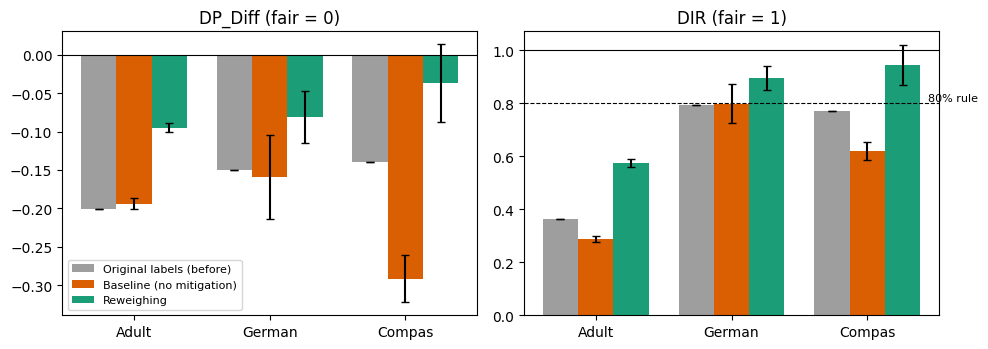

In [0]:
import matplotlib.pyplot as plt

stages = ["Original labels (before)", "Baseline (no mitigation)", "Reweighing"]
colors = ["#9e9e9e", "#d95f02", "#1b9e77"]
names = list(datasets.keys())
std = res.groupby(["dataset", "variant"])[["DP_Diff", "DIR"]].std()
x = np.arange(len(names)); bw = 0.26
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, metric, ideal in [(axes[0], "DP_Diff", 0.0), (axes[1], "DIR", 1.0)]:
    for i, (stage, col) in enumerate(zip(stages, colors)):
        vals = [comparison.query("dataset == @n and variant == @stage")[metric].item() for n in names]
        err = [0 if stage == stages[0] else std.loc[(n, stage), metric] for n in names]
        ax.bar(x + (i - 1) * bw, vals, bw, yerr=err, capsize=3, color=col, label=stage)
    ax.axhline(ideal, color="black", lw=0.8)
    if metric == "DIR":
        ax.axhline(0.8, color="black", ls="--", lw=0.8); ax.text(len(names) - 0.55, 0.81, "80% rule", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels([n.capitalize() for n in names]); ax.set_title(f"{metric} (fair = {ideal:g})")
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig("fairness_before_after.png", dpi=200, bbox_inches="tight")
plt.show()

## Conclusions
* All three datasets favour the privileged group in their original labels. The unmitigated classifier keeps this bias and makes it worse on Adult (DIR) and COMPAS (DP_Diff).
* Reweighing reduces the demographic parity gap on every dataset and brings German and COMPAS above the 80 % rule. Adult improves but stays below 0.8, because proxy features (relationship, marital status) still carry sex information.
* The accuracy cost is small (0.4–1.3 percentage points). Consistency (individual fairness) is essentially unchanged, which fits a method that targets group parity only.
* See the report for the full discussion and parameter settings.